In [ ]:
5.2: Noise Reduction Filters

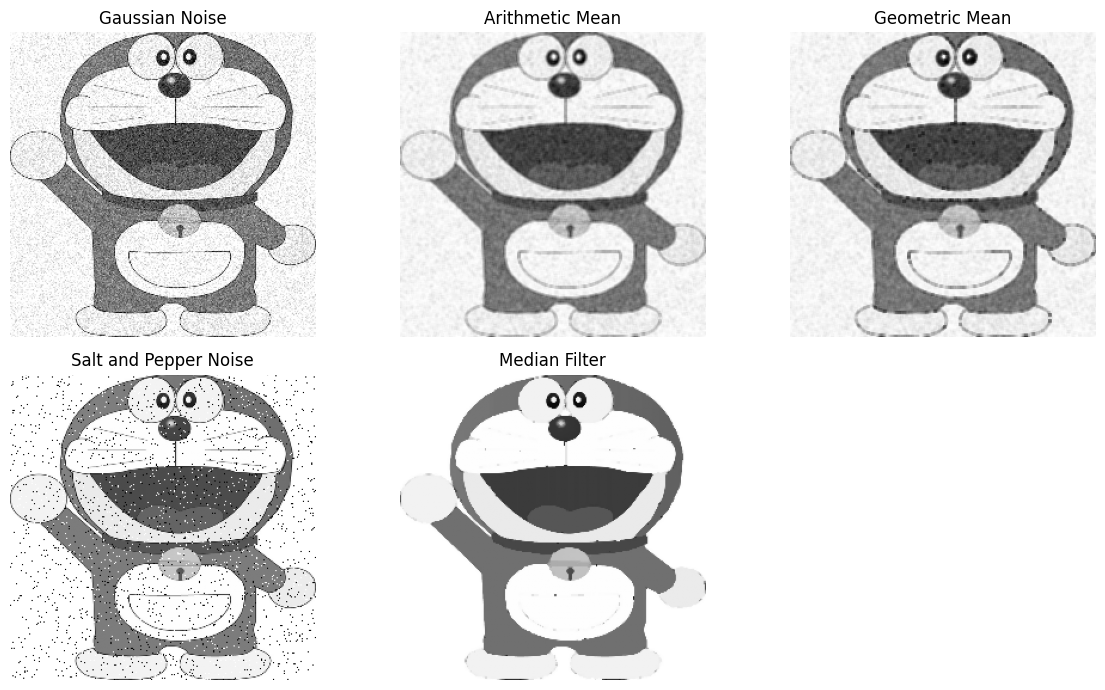

Assignment 5.2 Completed!


In [6]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Load Original Image
img = cv2.imread('/content/image.png', 0)

if img is None:
    raise ValueError("Please upload image.png")

img = cv2.resize(img, (256, 256))

# Add Gaussian Noise
noise = np.random.normal(0, 25, img.shape)
gaussian_img = np.clip(
    img.astype(float) + noise, 0, 255
).astype(np.uint8)

# Add Salt and Pepper Noise
sp_img = img.copy()
total = img.size
num = int(0.05 * total)

pixels = np.random.choice(total, num, replace=False)
half = num // 2

sp_img.flat[pixels[:half]] = 255
sp_img.flat[pixels[half:]] = 0

# 1. Arithmetic Mean Filter
arithmetic = cv2.blur(gaussian_img, (3, 3))

# 2. Geometric Mean Filter
def geometric_mean(image):
    log_img = np.log(image.astype(float) + 1)
    mean_log = cv2.blur(log_img, (3, 3))
    result = np.exp(mean_log) - 1
    return np.clip(result, 0, 255).astype(np.uint8)

geometric = geometric_mean(gaussian_img)

# 3. Median Filter
median = cv2.medianBlur(sp_img, 3)

# Display Results
plt.figure(figsize=(12, 7))

plt.subplot(2, 3, 1)
plt.imshow(gaussian_img, cmap='gray')
plt.title("Gaussian Noise")
plt.axis('off')

plt.subplot(2, 3, 2)
plt.imshow(arithmetic, cmap='gray')
plt.title("Arithmetic Mean")
plt.axis('off')

plt.subplot(2, 3, 3)
plt.imshow(geometric, cmap='gray')
plt.title("Geometric Mean")
plt.axis('off')

plt.subplot(2, 3, 4)
plt.imshow(sp_img, cmap='gray')
plt.title("Salt and Pepper Noise")
plt.axis('off')

plt.subplot(2, 3, 5)
plt.imshow(median, cmap='gray')
plt.title("Median Filter")
plt.axis('off')

plt.tight_layout()
plt.show()

# Save Results
cv2.imwrite('/content/Arithmetic_Mean.png', arithmetic)
cv2.imwrite('/content/Geometric_Mean.png', geometric)
cv2.imwrite('/content/Median_Filter.png', median)

print("Assignment 5.2 Completed!")
